In [17]:
import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv("ad_spend.csv")
df.head(3)

,Ad Spend ($),Season,Revenue ($)
0,463,Monsoon,440
1,158,Winter,297
2,328,Monsoon,214


In [18]:
df.shape

(200, 3)

In [19]:
g = df.groupby("Season")[["Ad Spend ($)", "Revenue ($)"]].mean()
g

,Ad Spend ($),Revenue ($)
Season,,
Monsoon,517.643836,423.150685
Summer,573.836066,689.360656
Winter,552.560606,826.530303


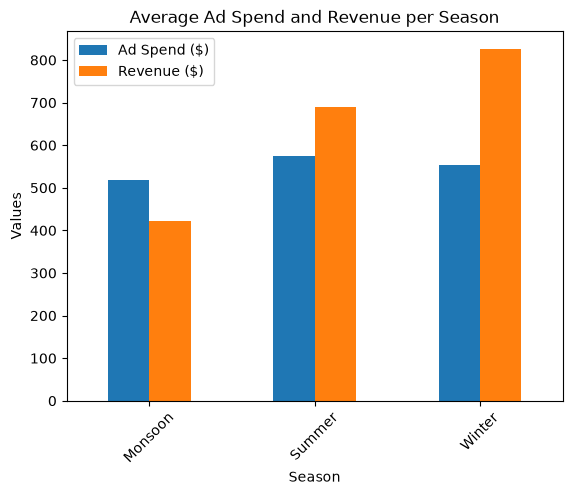

In [20]:
ax = g.plot(kind='bar')

ax.set_title("Average Ad Spend and Revenue per Season")
ax.set_xlabel("Season")
ax.set_ylabel("Values")

plt.xticks(rotation=45)
plt.show()

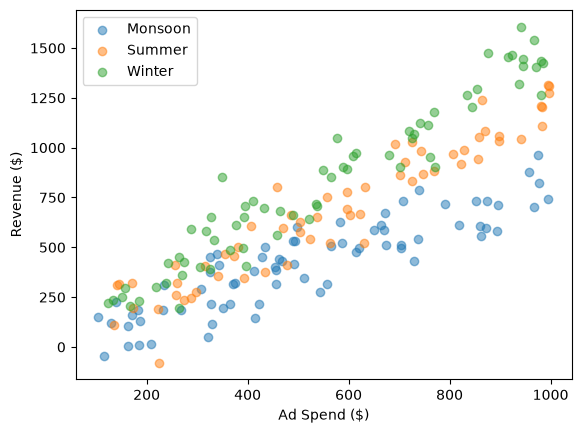

In [21]:
for season, subf in df.groupby("Season"):
    plt.scatter(subf["Ad Spend ($)"], subf["Revenue ($)"], label=season, alpha=0.5)
    
plt.xlabel("Ad Spend ($)")
plt.ylabel("Revenue ($)")
plt.legend()
plt.show()

In [22]:
df_encoded = pd.get_dummies(df, columns=["Season"], drop_first=True)
df_encoded.head()

,Ad Spend ($),Revenue ($),Season_Summer,Season_Winter
0,463,440,False,False
1,158,297,False,True
2,328,214,False,False
3,322,48,False,False
4,726,1048,False,True


In [23]:
from sklearn.model_selection import train_test_split

X = df_encoded[["Ad Spend ($)", "Season_Summer", "Season_Winter"]]
y = df_encoded["Revenue ($)"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)

### Train Linear Regression Model

In [24]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
model.score(X_test, y_test)

0.8882097000477289

### Train GDM

In [25]:
from sklearn.ensemble import GradientBoostingRegressor

model = GradientBoostingRegressor()
model.fit(X_train, y_train)
model.score(X_test, y_test)

0.9149899654766234

In [27]:
y_pred = model.predict(X_test)

df_eval = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df.eval

<bound method DataFrame.eval of      Ad Spend ($)   Season  Revenue ($)
0             463  Monsoon          440
1             158   Winter          297
2             328  Monsoon          214
3             322  Monsoon           48
4             726   Winter         1048
..            ...      ...          ...
195           407   Summer          609
196           182  Monsoon          183
197           184  Monsoon           10
198           380   Summer          504
199           981   Winter         1266

[200 rows x 3 columns]>

In [28]:
df_eval['Diff %'] = abs((df_eval['Predicted'] - df_eval['Actual'])*100/df_eval['Actual'])
df_eval

,Actual,Predicted,Diff %
59,605,677.144222,11.924665
5,1125,1073.575312,4.571083
20,699,626.698237,10.343600
198,504,418.202801,17.023254
52,1310,1134.088133,13.428387
19,320,170.512121,46.714962
162,944,1016.629203,7.693771
55,581,747.372975,28.635624
69,1446,1419.638973,1.823031
2,214,344.868149,61.153341
